# Práctica 002: SVR para predecir ventas diarias

La portada (sección 0) la completa R4. Este archivo tiene las secciones 1 a 3 de R1 (aprobadas, sin cambios) y las secciones 4 a 6 de R2 (Modelado y MLflow).

## 1. Configuración

Imports, rutas, semilla (`SEED = 42`) y versiones. `raiz_proyecto()` encuentra el repositorio aunque el kernel arranque en `src/` o en `src/<nombre>/`. La tabla compara las versiones instaladas con `requirements.txt` y `.python-version`: la celda falla solo si difiere Python o una librería que afecta a los resultados (`CLAVE`); `jupyterlab`, `nbconvert` e `ipykernel` se muestran como aviso. El único filtro de avisos es el de `vert=`, que emite seaborn 0.13.2 con matplotlib 3.11 y no depende de este código.

In [1]:
%matplotlib inline
import importlib.metadata
import platform
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib import MatplotlibDeprecationWarning

# seaborn 0.13.2 pasa vert= a matplotlib, deprecado en 3.11.
warnings.filterwarnings("ignore", message=r".*vert.*deprecated.*", category=MatplotlibDeprecationWarning)
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")


def raiz_proyecto():
    # Primera carpeta hacia arriba con datos/ventas_features.csv: sirve desde la raíz, src/ o src/<nombre>/.
    aqui = Path.cwd().resolve()
    return next((p for p in [aqui, *aqui.parents] if (p / "datos" / "ventas_features.csv").exists()), None)


def guardar(fig, nombre):
    fig.savefig(RUTA_FIGURAS / nombre, dpi=150, bbox_inches="tight")


RAIZ = raiz_proyecto()
assert RAIZ, "No se encontró datos/ventas_features.csv: abre el notebook dentro del repositorio."
RUTA_DATOS, RUTA_RESULTADOS = RAIZ / "datos" / "ventas_features.csv", RAIZ / "resultados"
RUTA_FIGURAS = RUTA_RESULTADOS / "figuras"
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Versiones: falla solo si difiere Python o una librería que afecta a los resultados; el resto es aviso.
CLAVE = ["python", "numpy", "pandas", "scikit-learn", "joblib", "matplotlib", "seaborn", "mlflow"]
pines = [l.strip().split("==") for l in (RAIZ / "requirements.txt").read_text().splitlines() if "==" in l and l[0] != "#"]
requeridas = {"python": (RAIZ / ".python-version").read_text().strip(), **dict(pines)}
disponibles = {d.metadata["Name"].lower(): d.version for d in importlib.metadata.distributions()}
instaladas = {p: platform.python_version() if p == "python" else disponibles.get(p, "no instalado") for p in requeridas}
versiones = pd.DataFrame({"requerida": requeridas, "instalada": instaladas})
coincide = versiones["requerida"] == versiones["instalada"]
versiones["estado"] = np.where(coincide, "ok", np.where(versiones.index.isin(CLAVE), "ERROR", "aviso"))
assert coincide[CLAVE].all(), "Python o una librería clave no coincide con requirements.txt"
versiones

,requerida,instalada,estado
python,3.12.7,3.12.7,ok
numpy,2.5.4,2.5.4,ok
pandas,3.0.6,3.0.6,ok
scikit-learn,1.9.1,1.9.1,ok
joblib,1.6.0,1.6.0,ok
matplotlib,3.11.2,3.11.2,ok
seaborn,0.13.2,0.13.2,ok
mlflow,3.18.0,3.18.0,ok
jupyterlab,4.6.6,4.6.6,ok
nbconvert,7.17.2,7.17.2,ok


## 2. Datos y EDA mínimo

Usamos `ventas_features.csv` (práctica 001): ventas diarias de 10 productos durante 60 días, con calendario, rezagos de ventas, stock y caducidad. El target `cantidad_vendida` es continuo (unidades por día), por eso el modelo es una regresión (SVR). El EDA usa el dataset completo; el modelado usa solo las filas sin nulos (sección 3.2).

### 2.1 Carga y validación

Cargamos el CSV con la fecha como fecha real y comprobamos con `assert` que tiene la forma esperada, sin duplicados y con rangos coherentes.

In [2]:
df_crudo = pd.read_csv(RUTA_DATOS, parse_dates=["fecha_venta"])
df_crudo = df_crudo.sort_values(["fecha_venta", "product_id"]).reset_index(drop=True)
df = df_crudo.copy()  # EDA sobre el dataset completo; en 3.2 df pasa a ser el dataset limpio

assert df.shape == (600, 22) and df["product_id"].nunique() == 10
assert (df.groupby("product_id")["fecha_venta"].nunique() == 60).all()
assert not df.duplicated(["product_id", "fecha_venta"]).any()
assert df["dia_semana"].between(0, 6).all() and (df["cantidad_vendida"] > 0).all()
assert df[["es_fin_de_semana", "es_feriado"]].isin([0, 1]).all().all()

resumen = df.agg(["min", "max"]).T
resumen.insert(0, "tipo", df.dtypes.astype(str))
resumen.insert(1, "nulos", df.isna().sum())
resumen.insert(2, "distintos", df.nunique())
resumen

,tipo,nulos,distintos,min,max
product_id,str,0,10,P0001,P0010
nombre,str,0,10,Aceite vegetal,Papel higiénico
categoria,str,0,6,Alimentos,Snacks
unidad,str,0,5,docena,unidad
fecha_venta,datetime64[us],0,60,2022-01-01 00:00:00,2022-03-01 00:00:00
anio,int64,0,1,2022,2022
mes,int64,0,3,1,3
dia_del_mes,int64,0,31,1,31
dia_semana,int64,0,7,0,6
nombre_dia,str,0,7,Domingo,Viernes


### 2.2 Valores nulos

El dataset original (`sales_history.csv`) no tiene nulos. Los de `ventas_features.csv` son estructurales: son el periodo de calentamiento de los rezagos, porque el día 1 de cada producto no tiene día anterior y los días 1 a 7 no tienen "hace 7 días". Son 90 celdas repartidas en 70 filas (el día 1 tiene 3 nulos y los días 2 a 7 tienen 1). Los `assert` lo comprueban y el mapa muestra dónde caen.

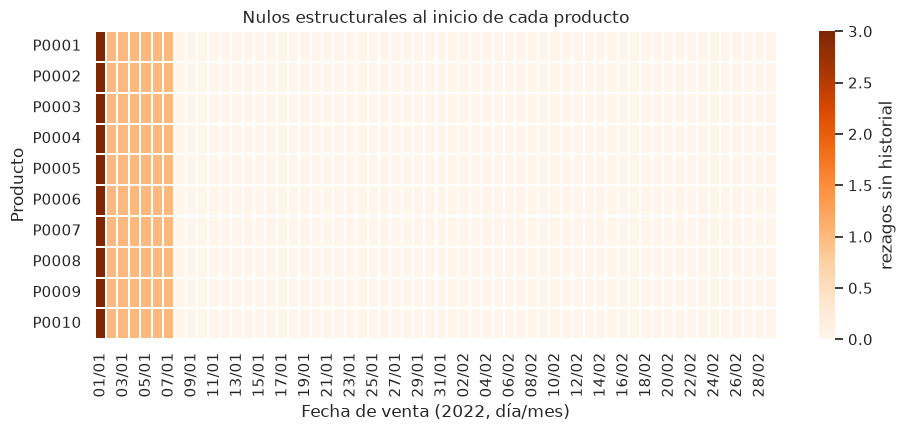

In [3]:
REZAGOS = ["ventas_dia_anterior", "ventas_hace_7_dias", "promedio_movil_7d"]
indice_dia = (df_crudo["fecha_venta"] - df_crudo["fecha_venta"].min()).dt.days  # 0 = primer día

assert pd.read_csv(RAIZ / "datos" / "sales_history.csv").isna().sum().sum() == 0  # el dato original no tiene nulos
assert df_crudo[REZAGOS].isna().sum().sum() == 90                      # 90 celdas de calentamiento
assert df_crudo[REZAGOS].isna().any(axis=1).sum() == 70                # concentradas en 70 filas
assert df_crudo["ventas_hace_7_dias"].isna().eq(indice_dia < 7).all()  # primeros 7 días de cada producto
assert df_crudo[["ventas_dia_anterior", "promedio_movil_7d"]].isna().all(axis=1).eq(indice_dia == 0).all()

mapa = df_crudo.assign(rezagos_nulos=df_crudo[REZAGOS].isna().sum(axis=1)).pivot(
    index="product_id", columns="fecha_venta", values="rezagos_nulos")
mapa.columns = mapa.columns.strftime("%d/%m")
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(mapa, cmap="Oranges", linewidths=0.3, linecolor="white", cbar_kws={"label": "rezagos sin historial"}, ax=ax)
ax.set(title="Nulos estructurales al inicio de cada producto", xlabel="Fecha de venta (2022, día/mes)", ylabel="Producto")
guardar(fig, "eda_nulos.png")
plt.show()

La decisión es eliminar esas filas (`dropna`, sección 3.2) y no imputarlas: rellenar un rezago con la media o con ceros inventaría ventas que no ocurrieron.

### 2.3 Distribución del target

¿Cómo se distribuyen las ventas y cuánto cambian según el día de la semana?

,count,mean,std,min,25%,50%,75%,max,asimetria
cantidad_vendida,600.0,151.2,57.8,67.0,110.0,140.5,172.0,411.0,1.43


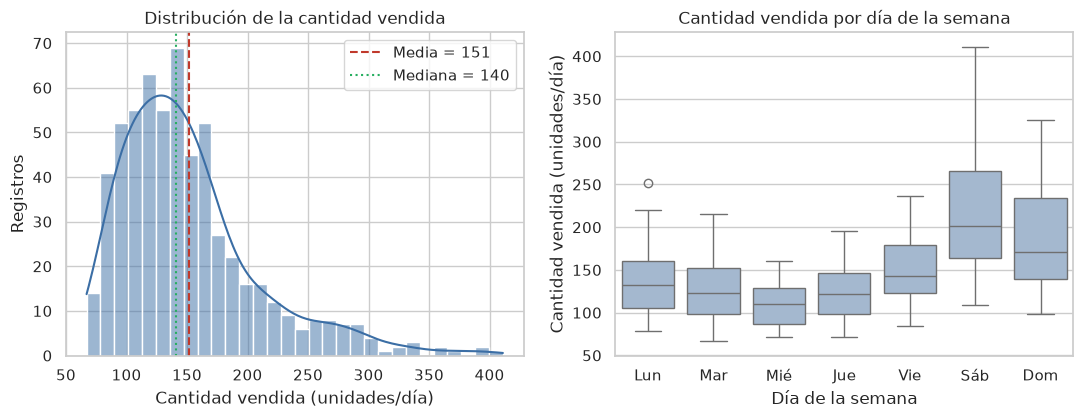

In [4]:
objetivo = df["cantidad_vendida"]
display(objetivo.describe().round(1).to_frame().T.assign(asimetria=round(objetivo.skew(), 2)))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(objetivo, bins=30, kde=True, color="#3b6ea5", ax=ejes[0])
ejes[0].axvline(objetivo.mean(), color="#c0392b", ls="--", label=f"Media = {objetivo.mean():.0f}")
ejes[0].axvline(objetivo.median(), color="#27ae60", ls=":", label=f"Mediana = {objetivo.median():.0f}")
ejes[0].set(title="Distribución de la cantidad vendida", xlabel="Cantidad vendida (unidades/día)", ylabel="Registros")
ejes[0].legend()
sns.boxplot(data=df, x="dia_semana", y="cantidad_vendida", color="#9db8d6", ax=ejes[1])
ejes[1].set_xticks(range(7), ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"])
ejes[1].set(title="Cantidad vendida por día de la semana", xlabel="Día de la semana", ylabel="Cantidad vendida (unidades/día)")
guardar(fig, "eda_distribucion.png")
plt.show()

Interpretación: la distribución tiene cola derecha (la media supera a la mediana) y el sábado y el domingo venden claramente más que entre semana. Por eso esperamos que `dia_semana` y `es_fin_de_semana` aporten, y por eso el target se escala dentro del pipeline (R2).

### 2.4 Ventas por categoría y producto

¿Cuánto cambia el nivel de ventas entre categorías y productos?

,productos,filas,media,desviacion
categoria,,,,
Bebidas,1,60,212.2,68.1
Snacks,1,60,199.5,67.6
Alimentos,5,300,150.0,48.7
Cuidado personal,1,60,123.6,27.5
Hogar,1,60,116.9,30.6
Limpieza,1,60,109.9,33.7


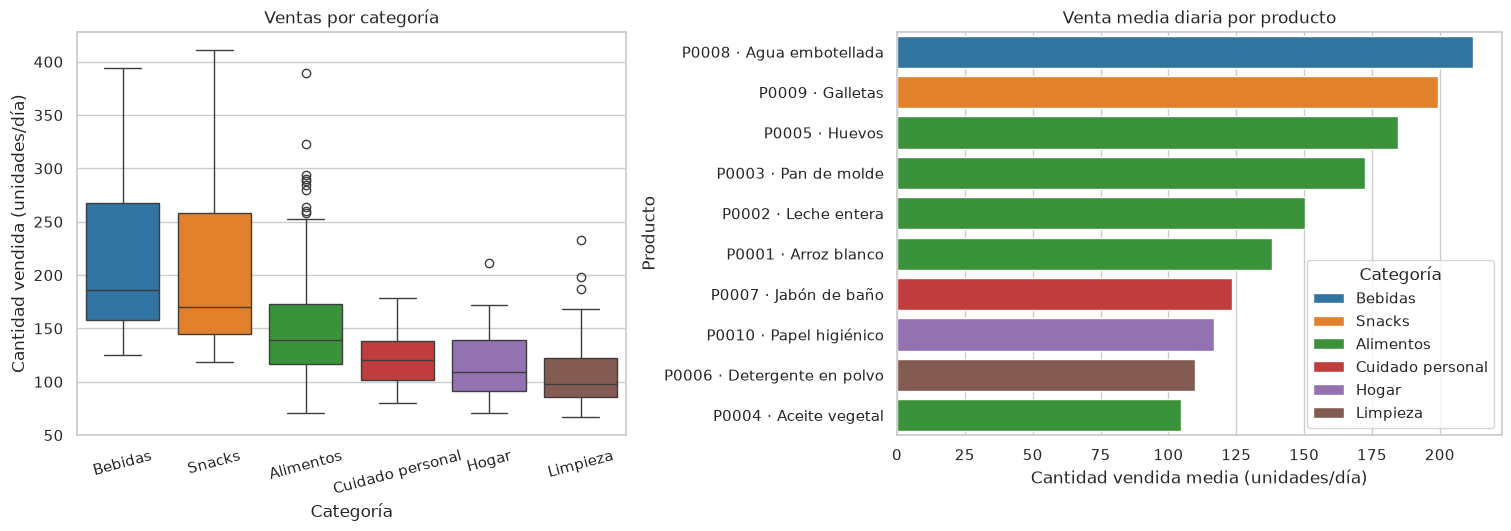

In [5]:
por_categoria = (
    df.groupby("categoria")
    .agg(productos=("product_id", "nunique"), filas=("cantidad_vendida", "size"),
         media=("cantidad_vendida", "mean"), desviacion=("cantidad_vendida", "std"))
    .round(1).sort_values("media", ascending=False)
)
display(por_categoria)
ORDEN_CATEGORIAS = por_categoria.index.tolist()
PALETA = dict(zip(ORDEN_CATEGORIAS, sns.color_palette("tab10", len(ORDEN_CATEGORIAS))))

por_producto = df.groupby(["product_id", "nombre", "categoria"], as_index=False)["cantidad_vendida"].mean()
por_producto["producto"] = por_producto["product_id"] + " · " + por_producto["nombre"]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.1]}, layout="constrained")
sns.boxplot(data=df, x="categoria", y="cantidad_vendida", order=ORDEN_CATEGORIAS, hue="categoria", palette=PALETA, legend=False, ax=ejes[0])
ejes[0].set(title="Ventas por categoría", xlabel="Categoría", ylabel="Cantidad vendida (unidades/día)")
ejes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=por_producto.sort_values("cantidad_vendida", ascending=False), x="cantidad_vendida", y="producto",
            hue="categoria", palette=PALETA, dodge=False, ax=ejes[1])
ejes[1].set(title="Venta media diaria por producto", xlabel="Cantidad vendida media (unidades/día)", ylabel="Producto")
ejes[1].legend(title="Categoría", loc="lower right")
guardar(fig, "eda_categoria.png")
plt.show()

Interpretación: Agua embotellada (Bebidas) y Galletas (Snacks) venden casi el doble que Detergente en polvo y Aceite vegetal, y su dispersión es mayor que la de Cuidado personal. Cinco de las seis categorías tienen un solo producto y Alimentos tiene cinco, así que `categoria` aporta lo mismo que `product_id`; se conserva por decisión del equipo (ver 3.1 y 3.6).

### 2.5 Evolución temporal

¿Hay tendencia, estacionalidad semanal o efecto de feriados?

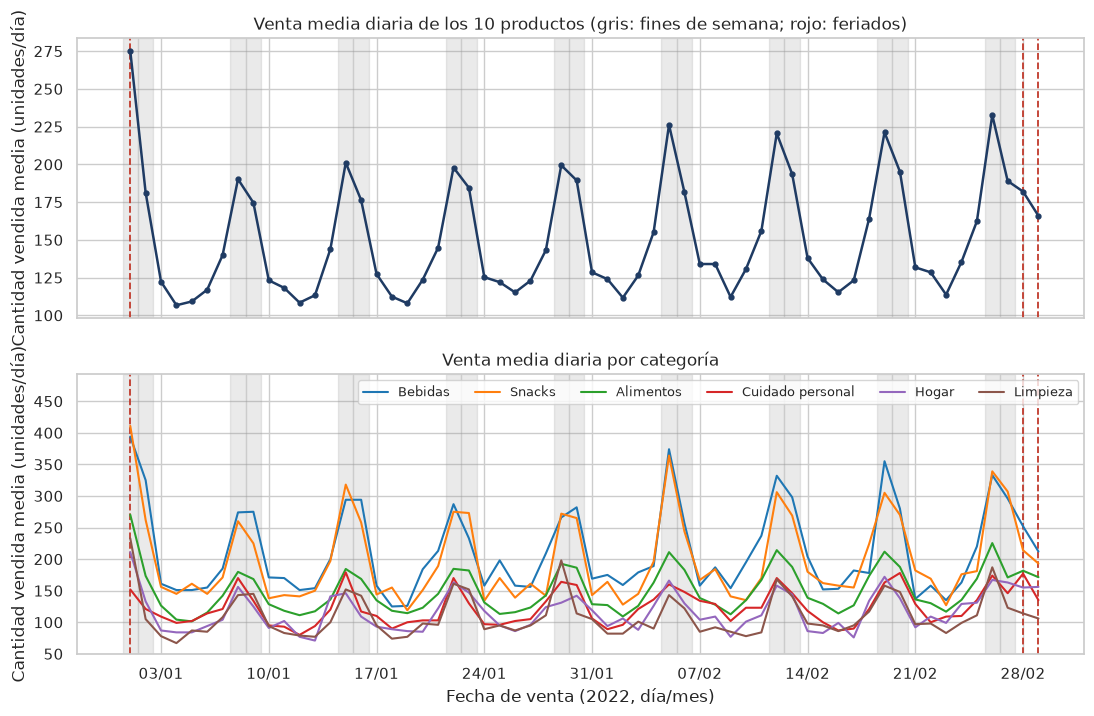

In [6]:
diario = df.groupby("fecha_venta")["cantidad_vendida"].mean()
por_categoria_dia = df.pivot_table(index="fecha_venta", columns="categoria", values="cantidad_vendida")
fines_de_semana = diario.index[diario.index.dayofweek >= 5]
feriados = df.loc[df["es_feriado"] == 1, "fecha_venta"].unique()

fig, ejes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax in ejes:
    for dia in fines_de_semana:
        ax.axvspan(dia - pd.Timedelta(hours=12), dia + pd.Timedelta(hours=12), color="#999999", alpha=0.2)
    for dia in feriados:
        ax.axvline(dia, color="#c0392b", ls="--", lw=1.3)
ejes[0].plot(diario, marker="o", ms=3.5, lw=1.8, color="#1f3b63")
ejes[0].set(title="Venta media diaria de los 10 productos (gris: fines de semana; rojo: feriados)", ylabel="Cantidad vendida media (unidades/día)")
for categoria in ORDEN_CATEGORIAS:
    ejes[1].plot(por_categoria_dia[categoria], lw=1.5, color=PALETA[categoria], label=categoria)
ejes[1].set(title="Venta media diaria por categoría", xlabel="Fecha de venta (2022, día/mes)", ylabel="Cantidad vendida media (unidades/día)",
            ylim=(None, por_categoria_dia.max().max() * 1.2))
ejes[1].legend(ncol=6, fontsize=9, loc="upper right")
ejes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
ejes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
guardar(fig, "eda_temporal.png")
plt.show()

Interpretación: la estacionalidad semanal es clara (pico el sábado, mínimo a mitad de semana) y no hay una tendencia marcada, salvo un leve aumento de los picos en febrero. `ventas_hace_7_dias` captura justamente ese patrón semanal.

Hay tres feriados: el 1-ene, que se pierde con `dropna` porque cae en el calentamiento de los rezagos, y el 28-feb y el 1-mar, que quedan en test. El modelo no ve ningún feriado en entrenamiento (ver 3.6).

## 3. Features y split

Regla del plan: ninguna variable puede contener información del futuro ni del target. R2, R3 y R4 reciben `X_train`, `X_test`, `y_train`, `y_test` y `COLUMNAS` sin modificarlos.

### 3.1 Variables

Entran 11 predictoras numéricas y dos categóricas en one-hot, `categoria` y `product_id`; el target es `cantidad_vendida`. `categoria` es función de `product_id`, pero se conserva por decisión del equipo (plan, sección 3.1); sus consecuencias se ven en 3.6. El resto se excluye:

| Columnas excluidas | Motivo |
|---|---|
| `anio`, `stock_actual`, `unidad` | `anio` es constante; `stock_actual` y `unidad` son fijas por producto y solo lo identifican |
| `nombre`, `nombre_dia`, `tipo_dia` | Texto redundante con `product_id`, `dia_semana` y `es_fin_de_semana`/`es_feriado` |
| `fecha_venta`, `semana_iso` | La fecha solo ordena y divide; `semana_iso` no es monótona (el 1-ene-2022 es la semana 52) |

In [7]:
NUM = ["mes", "dia_del_mes", "dia_semana", "es_fin_de_semana", "es_feriado", "semana_del_periodo",
       "ventas_dia_anterior", "ventas_hace_7_dias", "promedio_movil_7d", "stock_en_momento", "dias_para_expirar"]
CAT = ["categoria", "product_id"]  # categoria = f(product_id): se conserva por decisión del equipo (ver 3.6)
TARGET = "cantidad_vendida"
EXCLUIDAS = {
    "stock_actual": "constante por producto", "nombre": "1 a 1 con product_id",
    "unidad": "fija por producto", "fecha_venta": "solo ordena y divide", "anio": "constante",
    "nombre_dia": "1 a 1 con dia_semana", "tipo_dia": "derivada de es_fin_de_semana y es_feriado",
    "semana_iso": "no es monótona (1-ene = semana 52)",
}

assert set(NUM) | set(CAT) | set(EXCLUIDAS) | {TARGET} == set(df_crudo.columns)
assert df_crudo["anio"].nunique() == 1
assert df_crudo.groupby("product_id")[["categoria", "stock_actual", "nombre", "unidad"]].nunique().max().max() == 1
assert df_crudo.groupby("dia_semana")["nombre_dia"].nunique().max() == 1

roles = {**dict.fromkeys(NUM, "numérica"), **dict.fromkeys(CAT, "categórica"), TARGET: "target", **dict.fromkeys(EXCLUIDAS, "excluida")}
tabla_variables = pd.DataFrame({"rol": roles, "motivo_exclusion": pd.Series(EXCLUIDAS)}).loc[list(roles)].rename_axis("variable")
tabla_variables.to_csv(RUTA_RESULTADOS / "tabla_variables.csv")

### 3.2 Eliminación de filas con nulos

Aplicamos `dropna` sobre las predictoras numéricas y el target. Desde aquí `df` es el dataset limpio (el del modelado) y `df_crudo` conserva las filas originales, así que la celda se puede ejecutar de nuevo sin romper la auditoría de 3.5.

In [8]:
df = df_crudo.dropna(subset=NUM + [TARGET]).reset_index(drop=True)

assert len(df) == 530 and df[NUM + [TARGET]].notna().all().all()
assert (df.groupby("product_id").size() == 53).all()

pd.DataFrame(
    {"filas": [len(df_crudo), len(df)], "primer día": [d["fecha_venta"].min().date() for d in (df_crudo, df)],
     "último día": [d["fecha_venta"].max().date() for d in (df_crudo, df)]},
    index=["antes (EDA)", "después (modelado)"],
)

,filas,primer día,último día
antes (EDA),600,2022-01-01,2022-03-01
después (modelado),530,2022-01-08,2022-03-01


### 3.3 Matriz X y vector y

El SVR solo trabaja con números, así que `categoria` y `product_id` pasan a columnas 0/1 (one-hot). Con `drop_first=True`, Alimentos y P0001 quedan como referencia implícita: 11 numéricas + 5 dummies de `categoria` + 9 de `product_id` = 25 columnas. Verificamos que `X` no tenga nulos ni columnas constantes y que el target no esté entre las predictoras.

In [9]:
X = pd.get_dummies(df[NUM + CAT], columns=CAT, drop_first=True, dtype=float)
y = df[TARGET]

assert X.shape == (530, 25) and X.isna().sum().sum() == 0 and y.isna().sum() == 0
assert (X.nunique() > 1).all() and TARGET not in X.columns
assert X.select_dtypes("number").shape[1] == X.shape[1]

pd.Series({"filas": X.shape[0], "columnas": X.shape[1], "numéricas": len(NUM),
           "dummies de categoria": X.filter(like="categoria_").shape[1],
           "dummies de product_id": X.filter(like="product_id_").shape[1]}, name="X")

filas                    530
columnas                  25
numéricas                 11
dummies de categoria       5
dummies de product_id      9
Name: X, dtype: int64

### 3.4 Split temporal 80/20 y lista COLUMNAS

El split es por fecha, no aleatorio: uno aleatorio dejaría en train días vecinos de los de test y las métricas saldrían infladas. El corte es el cuantil 0,8 de `fecha_venta` y se hace por días completos, así que los 10 productos entran juntos. `COLUMNAS` guarda el orden de columnas que R3 necesita en `predecir_venta()`.

In [10]:
corte = df["fecha_venta"].quantile(0.8)
es_train = df["fecha_venta"] <= corte
X_train, y_train = X[es_train], y[es_train]
X_test, y_test = X[~es_train], y[~es_train]
COLUMNAS = X_train.columns.tolist()

assert df.loc[es_train, "fecha_venta"].max() < df.loc[~es_train, "fecha_venta"].min()  # sin solapamiento
assert set(df.loc[es_train, "product_id"]) == set(df.loc[~es_train, "product_id"])     # los 10 productos en ambos
assert abs(es_train.mean() - 0.8) < 0.02                                               # proporción cercana a 80/20
assert COLUMNAS == X_test.columns.tolist() and not X_train.isna().any().any() and not X_test.isna().any().any()

(df.assign(conjunto=np.where(es_train, "train", "test")).groupby("conjunto")
   .agg(filas=("fecha_venta", "size"), primer_dia=("fecha_venta", "min"), ultimo_dia=("fecha_venta", "max"),
        dias=("fecha_venta", "nunique"), productos=("product_id", "nunique"))
   .assign(porcentaje=lambda t: (t["filas"] / len(df) * 100).round(1)).loc[["train", "test"]])

,filas,primer_dia,ultimo_dia,dias,productos,porcentaje
conjunto,,,,,,
train,430,2022-01-08,2022-02-19,43,10,81.1
test,100,2022-02-20,2022-03-01,10,10,18.9


### 3.5 Revisión de fuga de información

Comprobamos con cálculos que ninguna predictora usa información del futuro ni del target. Cada control da verdadero o falso y la celda falla si alguno no se cumple.

In [11]:
ordenado = df_crudo.sort_values(["product_id", "fecha_venta"])
ventas = ordenado.groupby("product_id")["cantidad_vendida"]
media_previa = ventas.transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean())
media_con_hoy = ventas.transform(lambda s: s.rolling(7, min_periods=1).mean())
stock_esperado = ordenado.groupby("product_id")["stock_en_momento"].shift(1) - ventas.shift(1)
correlacion = df[NUM].corrwith(df[TARGET]).abs().sort_values(ascending=False)


def coincide(columna, esperado):
    """True si la columna vale lo esperado y los nulos están en las mismas filas."""
    presente = ordenado[columna].notna()
    return bool(np.array_equal(presente, esperado.notna()) and np.allclose(ordenado.loc[presente, columna], esperado[presente]))


controles = {
    "ventas_dia_anterior = venta del día previo": coincide("ventas_dia_anterior", ventas.shift(1)),
    "ventas_hace_7_dias = venta de 7 días antes": coincide("ventas_hace_7_dias", ventas.shift(7)),
    "promedio_movil_7d usa solo días previos": coincide("promedio_movil_7d", media_previa),
    "promedio_movil_7d no incluye el día actual": not coincide("promedio_movil_7d", media_con_hoy),
    "stock_en_momento no descuenta las ventas del propio día": bool(((ordenado["stock_en_momento"] - stock_esperado).dropna() >= 0).all()),
    "stock_actual es constante por producto (excluida)": bool((ordenado.groupby("product_id")["stock_actual"].nunique() == 1).all()),
    "el target no está en X": TARGET not in X.columns,
    f"ninguna predictora con |r| ≥ 0,95 (máxima: {correlacion.index[0]}, {correlacion.iloc[0]:.2f})": bool(correlacion.max() < 0.95),
    "las fechas de train son anteriores a las de test": bool(df.loc[es_train, "fecha_venta"].max() < df.loc[~es_train, "fecha_venta"].min()),
}
assert all(controles.values()), "Hay un control de fuga que no se cumple"
pd.Series(controles, name="cumple").map({True: "✔", False: "✘"}).to_frame()

,cumple
ventas_dia_anterior = venta del día previo,✔
ventas_hace_7_dias = venta de 7 días antes,✔
promedio_movil_7d usa solo días previos,✔
promedio_movil_7d no incluye el día actual,✔
stock_en_momento no descuenta las ventas del propio día,✔
stock_actual es constante por producto (excluida),✔
el target no está en X,✔
"ninguna predictora con |r| ≥ 0,95 (máxima: ventas_hace_7_dias, 0.89)",✔
las fechas de train son anteriores a las de test,✔


Resultado: los rezagos usan solo días previos y `stock_en_momento` es el inventario al inicio del día, así que ninguna variable usa información del futuro.

### 3.6 Diagnóstico para R2 y R4

Con un split temporal, algunas variables salen del rango de train. La tabla muestra qué porcentaje de test queda fuera de ese rango.

In [12]:
riesgo = ["es_feriado", "mes", "semana_del_periodo", "dias_para_expirar", "stock_en_momento", "dia_del_mes"]
rangos = X_train[riesgo].agg(["min", "max"]).T.join(X_test[riesgo].agg(["min", "max"]).T, lsuffix="_train", rsuffix="_test")
fuera_de_rango = (X_test[riesgo] < X_train[riesgo].min()) | (X_test[riesgo] > X_train[riesgo].max())
rangos["porcentaje_test_fuera"] = (fuera_de_rango.mean() * 100).round(1)
rangos

,min_train,max_train,min_test,max_test,porcentaje_test_fuera
es_feriado,0,0,0,1,20.0
mes,1,2,2,3,10.0
semana_del_periodo,2,8,8,9,40.0
dias_para_expirar,82,383,72,340,10.0
stock_en_momento,259,799,290,799,0.0
dia_del_mes,1,31,1,28,0.0


Las 5 dummies de `categoria` que entran al modelo son copias exactas de otras tantas de `product_id` (P0006 a P0010, cada una único producto de su categoría). Se conservan por decisión del equipo: en el kernel lineal producen colinealidad exacta y en RBF duplican el peso de la identidad del producto en la distancia. P0002 a P0005 no se duplican porque `categoria_Alimentos` es la de referencia y sería su suma. La tabla muestra cada par.

In [13]:
duplicadas = X.T[X.T.duplicated()].index.tolist()
copia_de = {c: next(o for o in X if o != c and X[o].equals(X[c])) for c in duplicadas}

assert X.T.duplicated().sum() == 5
pd.Series(copia_de, name="idéntica a").rename_axis("columna duplicada en X").to_frame()

,idéntica a
columna duplicada en X,
product_id_P0006,categoria_Limpieza
product_id_P0007,categoria_Cuidado personal
product_id_P0008,categoria_Bebidas
product_id_P0009,categoria_Snacks
product_id_P0010,categoria_Hogar


Hallazgos para el equipo:

- `es_feriado` vale 0 en train: el 1-ene se pierde con `dropna` y el 28-feb y el 1-mar caen en test, así que el modelo no aprende el efecto de un feriado y el caso de demanda alta de `predecir_venta()` no puede apoyarse en esa variable.
- `mes`, `semana_del_periodo` y `dias_para_expirar` salen del rango de train (primera tabla): riesgo de extrapolación.
- `X` tiene 25 columnas y 5 de ellas están duplicadas (`categoria` repite a `product_id`). Se conservan por decisión del equipo: en el kernel lineal hay colinealidad exacta y en RBF el producto pesa el doble en la distancia.
- Test tiene 100 filas y 10 días: las métricas serán ruidosas, conviene reportar también el RMSE de validación cruzada.
- En test los rezagos usan ventas reales del día anterior: es un pronóstico a 1 día, no a varios (importante al comparar con el LSTM de la práctica 001).

## 4. Pipeline SVR

### 4.1 Aprobación del control de fuga

El plan pide que R2 apruebe el split y el control de fuga de R1 antes de modelar (matriz 5.3 y regla 5.5). La celda vuelve a comprobar, sobre los mismos objetos que va a usar el modelo, que los 9 controles de la sección 3.5 se cumplen, que train termina antes de que empiece test y que `X_train` y `X_test` tienen exactamente las 25 columnas de `COLUMNAS`, sin el target.

In [14]:
fechas_train, fechas_test = df.loc[es_train, "fecha_venta"], df.loc[~es_train, "fecha_venta"]
aprobacion = {
    "los 9 controles de fuga de la sección 3.5 se cumplen": len(controles) == 9 and all(controles.values()),
    f"train termina ({fechas_train.max().date()}) antes de que empiece test ({fechas_test.min().date()})": fechas_train.max() < fechas_test.min(),
    "X_train y X_test tienen las 25 columnas de COLUMNAS": list(X_train) == list(X_test) == COLUMNAS and len(COLUMNAS) == 25,
    "el target no está entre las predictoras": TARGET not in COLUMNAS,
}
assert all(aprobacion.values()), "R2 no puede aprobar el split: revisar la sección 3.5"
pd.Series(aprobacion, name="cumple").map({True: "✔", False: "✘"}).to_frame()

,cumple
los 9 controles de fuga de la sección 3.5 se cumplen,✔
train termina (2022-02-19) antes de que empiece test (2022-02-20),✔
X_train y X_test tienen las 25 columnas de COLUMNAS,✔
el target no está entre las predictoras,✔


Con los cuatro controles en ✔, R2 aprueba el split temporal y el control de fuga de R1: el modelado de las secciones 5 y 6 parte de `X_train`, `X_test`, `y_train` y `y_test` sin modificarlos.

### 4.2 Constructor del modelo

`construir_svr()` arma el modelo que usan el barrido y la optimización. `StandardScaler` estandariza `X` dentro del pipeline (se ajusta solo con los datos de entrenamiento de cada `fit`), y `TransformedTargetRegressor` estandariza también `y`. Escalar el target importa en SVR: `epsilon` es una banda de tolerancia en unidades del target, y con ventas de 67 a 411 unidades un `epsilon=0.1` obligaría a ajustar casi cada punto. Con `y` estandarizado, `epsilon` y `C` se leen en desviaciones estándar y son comparables entre corridas. Las predicciones vuelven solas a unidades/día.

In [15]:
import sklearn
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR


def construir_svr(kernel="rbf", C=1.0, epsilon=0.1, gamma="scale", degree=3):
    """SVR con X e y estandarizados; las predicciones salen en unidades/día."""
    return TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), SVR(kernel=kernel, C=C, epsilon=epsilon, gamma=gamma, degree=degree)),
        transformer=StandardScaler(),
    )


assert "regressor__svr__C" in construir_svr().get_params()  # prefijo que usa el param_grid de la sección 6
construir_svr()

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.","Pipeline(step...svr', SVR())])"
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",StandardScaler()
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",None
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to

## 5. Barrido kernels × C con MLflow

### 5.1 Configuración de MLflow

El tracking usa SQLite (`mlflow.db`), porque el Model Registry necesita un backend SQL, y los artefactos van a `mlartifacts/`; los dos quedan en la raíz del proyecto y no se suben a Git. Cada corrida será un run del experimento `svr_ventas` y una versión del modelo registrado `svr_ventas`. El registry es el histórico de entrenamientos y no se limpia: volver a ejecutar agrega 17 versiones nuevas y mueve `champion` a la nueva versión del `GridSearchCV`, y el histórico queda visible en `mlflow ui`. Por eso la celda guarda en `version_inicial` el último número de versión que ya existe, y todas las comprobaciones de las secciones 5 y 6 se cuentan desde ahí.

Para validar la configuración (tarea 1 del plan) se crea un run de prueba: se escribe una métrica, se lee de vuelta desde la base y el run se borra. Así se comprueba que el tracking funciona sin agregar un run a los 17 de esta ejecución que verifica la sección 6.4.

`evaluar()` calcula las métricas del plan sobre test, y `rmse_cv()` el RMSE de validación cruzada con los mismos 5 folds que usará `GridSearchCV`, para comparar todas las versiones con la misma vara.

In [16]:
import contextlib
import io
import logging
import os

import joblib
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
for registro in ("mlflow", "alembic"):
    logging.getLogger(registro).setLevel(logging.ERROR)

NOMBRE = "svr_ventas"
mlflow.set_tracking_uri(f"sqlite:///{RAIZ / 'mlflow.db'}")
cliente = MlflowClient()
if cliente.get_experiment_by_name(NOMBRE) is None:
    cliente.create_experiment(NOMBRE, artifact_location=(RAIZ / "mlartifacts").as_uri())
experimento = mlflow.set_experiment(NOMBRE)

# El registry no se limpia: las versiones de esta ejecución se numeran a partir de la última existente.
version_inicial = max((int(v.version) for v in cliente.search_model_versions(f"name='{NOMBRE}'")), default=0)

# Run de prueba: escribe una métrica, la lee desde mlflow.db y se borra (no cuenta entre los 17 runs).
with mlflow.start_run(run_name="prueba_configuracion") as prueba:
    mlflow.log_metric("prueba", 1.0)
assert cliente.get_run(prueba.info.run_id).data.metrics == {"prueba": 1.0}, "El tracking de MLflow no guarda métricas"
cliente.delete_run(prueba.info.run_id)

RUTA_MODELOS = RUTA_RESULTADOS / "modelos"
RUTA_MODELOS.mkdir(parents=True, exist_ok=True)
for viejo in RUTA_MODELOS.glob("*.joblib"):
    viejo.unlink()

CV = KFold(5, shuffle=True, random_state=SEED)


def evaluar(y_real, pred):
    return {"rmse": float(np.sqrt(mean_squared_error(y_real, pred))), "mae": float(mean_absolute_error(y_real, pred)),
            "r2": float(r2_score(y_real, pred)), "mape": float(mean_absolute_percentage_error(y_real, pred) * 100)}


def registrar(info):
    """Registra el modelo del run como nueva versión de svr_ventas (silencia el aviso por consola de MLflow)."""
    with contextlib.redirect_stderr(io.StringIO()):
        return str(mlflow.register_model(info.model_uri, NOMBRE).version)


def rmse_cv(modelo):
    return float(-cross_val_score(modelo, X_train, y_train, cv=CV, scoring="neg_root_mean_squared_error").mean())


pd.Series({"tracking": mlflow.get_tracking_uri().replace(str(RAIZ), "<raíz>"), "experimento": experimento.name,
           "artefactos": experimento.artifact_location.replace(RAIZ.as_uri(), "<raíz>"),
           "run de prueba": "ok (escrito, leído y borrado)",
           "runs de ejecuciones anteriores": len(cliente.search_runs([experimento.experiment_id])),
           "versiones ya registradas (versión inicial)": version_inicial}, name="MLflow")

tracking                                         sqlite:///<raíz>/mlflow.db
experimento                                                      svr_ventas
artefactos                                               <raíz>/mlartifacts
run de prueba                                 ok (escrito, leído y borrado)
runs de ejecuciones anteriores                                            0
versiones ya registradas (versión inicial)                                0
Name: MLflow, dtype: object

### 5.2 Barrido: 4 kernels × 4 valores de C

Se entrenan 16 modelos con `epsilon=0.1`, `gamma="scale"` y `degree=3` (valores por defecto), variando solo el kernel y `C`. El baseline del plan (`linear`, C=1) es el primer run, así que queda como la primera versión de la ejecución; no se crea un run extra. Los números de versión que citan los textos (v1, v7, v17) son los de la ejecución entregada, hecha con un `mlflow.db` limpio; en una nueva ejecución MLflow sigue numerando (v18 a v34, y así). Cada iteración:

1. entrena con `X_train` y evalúa en `X_test` (RMSE, MAE, R², MAPE) y con validación cruzada (`rmse_cv`);
2. registra parámetros, métricas y el modelo en un run de MLflow;
3. registra el modelo como nueva versión de `svr_ventas`, con los tags `kernel` y `C`;
4. guarda una copia en `resultados/modelos/<kernel>_C<C>.joblib` para revisarla sin MLflow.

In [17]:
KERNELS, VALORES_C = ["linear", "rbf", "poly", "sigmoid"], [0.1, 1, 10, 100]
combinaciones = [("linear", 1)] + [(k, c) for k in KERNELS for c in VALORES_C if (k, c) != ("linear", 1)]
EJEMPLO = X_train.head(3).astype(float)  # firma de entrada del modelo registrado (todo float)
filas = []

for kernel, C in combinaciones:
    with mlflow.start_run(run_name=f"{kernel}_C{C}") as run:
        modelo = construir_svr(kernel=kernel, C=C).fit(X_train, y_train)
        metricas = {**evaluar(y_test, modelo.predict(X_test)), "rmse_cv": rmse_cv(construir_svr(kernel=kernel, C=C))}
        mlflow.log_params({"kernel": kernel, "C": C, "epsilon": 0.1, "gamma": "scale", "degree": 3,
                           "split": "temporal", "target": TARGET, "random_state": SEED, "sklearn": sklearn.__version__})
        mlflow.log_metrics(metricas)
        info = mlflow.sklearn.log_model(modelo, name="modelo", input_example=EJEMPLO)
        version = registrar(info)
        for etiqueta, valor in {"kernel": kernel, "C": str(C), "origen": "barrido"}.items():
            cliente.set_model_version_tag(NOMBRE, version, etiqueta, valor)
        joblib.dump(modelo, RUTA_MODELOS / f"{kernel}_C{C}.joblib")
    filas.append({"version": int(version), "kernel": kernel, "C": C, **metricas, "run": run.info.run_id})

barrido = pd.DataFrame(filas).set_index("version")
assert len(barrido) == 16 and list(barrido.index) == list(range(version_inicial + 1, version_inicial + 17))
barrido.drop(columns="run").round(3)

,kernel,C,rmse,mae,r2,mape,rmse_cv
version,,,,,,,
1,linear,1.0,26.266,20.124,0.768,12.305,20.740
2,linear,0.1,26.734,20.566,0.759,12.530,21.056
3,linear,10.0,26.256,20.080,0.768,12.295,20.765
4,linear,100.0,26.270,20.084,0.768,12.294,20.761
5,rbf,0.1,37.151,25.191,0.536,13.692,31.844
6,rbf,1.0,26.459,20.196,0.764,11.996,20.224
7,rbf,10.0,30.150,22.413,0.694,13.593,20.463
8,rbf,100.0,36.975,29.017,0.540,17.927,22.670
9,poly,0.1,31.016,24.551,0.676,14.481,28.277


### 5.3 Baseline y comparación por kernel

El punto de partida es la primera versión del barrido (`linear`, C=1). Como referencia sin modelo se agrega un baseline ingenuo: predecir con `promedio_movil_7d`, que ya está en los datos. La tabla de abajo cruza kernel y `C` con el RMSE de test.

In [18]:
ingenuo = evaluar(y_test, df.loc[~es_train, "promedio_movil_7d"])
punto_partida = pd.DataFrame([ingenuo, barrido.loc[barrido.index[0], list(ingenuo)]],
                             index=["ingenuo (promedio_movil_7d)", f"v{barrido.index[0]}: linear, C=1"]).round(2)
display(punto_partida)
barrido.pivot(index="kernel", columns="C", values="rmse").loc[KERNELS].round(2)

,rmse,mae,r2,mape
ingenuo (promedio_movil_7d),41.72,31.42,0.41,18.39
"v1: linear, C=1",26.27,20.12,0.77,12.30


C,0.1,1.0,10.0,100.0
kernel,,,,
linear,26.73,26.27,26.26,26.27
rbf,37.15,26.46,30.15,36.97
poly,31.02,35.26,40.47,53.67
sigmoid,31.30,93.92,1477.78,10485.82


Interpretación del barrido:

- Los cuatro modelos lineales y el `rbf` con C=1 mejoran mucho al baseline ingenuo: el RMSE de test baja de 41.7 a entre 26.3 y 26.7 unidades/día y el R² sube de 0.41 a 0.76–0.77.
- `linear` casi no depende de `C` (26.3 a 26.7): la venta se explica en buena parte por relaciones lineales con los rezagos, sobre todo `ventas_hace_7_dias`.
- `rbf` funciona mejor con C=1 (26.5). Con C=10 el RMSE de CV casi no cambia (20.5) pero el de test sube a 30.2: el modelo más flexible extrapola peor hacia días futuros. Con C=100 empeoran los dos (22.7 en CV y 37.0 en test), señal de sobreajuste.
- `poly` empeora a medida que crece `C` (de 31.0 a 53.7): con grado 3 extrapola mal los valores de test que quedan fuera del rango de train (sección 3.6).
- `sigmoid` es inestable y se reporta tal cual: con C=0.1 da un RMSE de 31.3, pero con C=1, 10 y 100 sube a 93.9, 1 477.8 y 10 485.8, con R² muy negativos. Este kernel no es definido positivo para la mayoría de sus parámetros y, al darle más peso a los errores (C alto), el modelo produce predicciones absurdas. Por eso no entra en la búsqueda de la sección 6.

## 6. Optimización con GridSearchCV

### 6.1 Búsqueda de hiperparámetros

`GridSearchCV` prueba combinaciones de `C`, `epsilon`, `gamma` y `degree` para `linear`, `rbf` y `poly` (el `param_grid` del plan, sección 7.7) con validación cruzada de 5 folds sobre train y elige por RMSE. `sigmoid` queda fuera por lo visto en el barrido. Con `refit=True` (valor por defecto), el mejor modelo se reentrena con todo `X_train`.

In [19]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {"regressor__svr__kernel": ["linear"], "regressor__svr__C": [0.1, 1, 10, 100], "regressor__svr__epsilon": [0.01, 0.1, 0.5]},
    {"regressor__svr__kernel": ["rbf"], "regressor__svr__C": [0.1, 1, 10, 100], "regressor__svr__epsilon": [0.01, 0.1, 0.5],
     "regressor__svr__gamma": ["scale", 0.01, 0.1]},
    {"regressor__svr__kernel": ["poly"], "regressor__svr__C": [0.1, 1, 10], "regressor__svr__epsilon": [0.1, 0.5],
     "regressor__svr__gamma": ["scale", 0.1], "regressor__svr__degree": [2, 3]},
]
gs = GridSearchCV(construir_svr(), param_grid, cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
mejor_modelo = gs.best_estimator_
mejores = {k.removeprefix("regressor__svr__"): v for k, v in gs.best_params_.items()}

resultados_cv = pd.DataFrame(gs.cv_results_)
top = (resultados_cv.assign(rmse_cv=-resultados_cv["mean_test_score"], desviacion=resultados_cv["std_test_score"])
       .sort_values("rmse_cv").head(5)[["params", "rmse_cv", "desviacion"]])
top["params"] = top["params"].map(lambda p: {k.removeprefix("regressor__svr__"): v for k, v in p.items()})
display(pd.Series({"combinaciones probadas": len(resultados_cv), "mejores parámetros": mejores,
                   "RMSE CV del mejor": round(-gs.best_score_, 2)}, name="GridSearchCV"))
top.round(2).reset_index(drop=True)

combinaciones probadas                                                   72
mejores parámetros        {'C': 10, 'epsilon': 0.1, 'gamma': 0.01, 'kern...
RMSE CV del mejor                                                     19.04
Name: GridSearchCV, dtype: object

,params,rmse_cv,desviacion
0,"{'C': 10, 'epsilon': 0.1, 'gamma': 0.01, 'kern...",19.04,1.50
1,"{'C': 100, 'epsilon': 0.1, 'gamma': 0.01, 'ker...",19.22,1.51
2,"{'C': 10, 'epsilon': 0.01, 'gamma': 0.01, 'ker...",19.62,1.58
3,"{'C': 10, 'degree': 2, 'epsilon': 0.1, 'gamma'...",20.08,0.39
4,"{'C': 100, 'epsilon': 0.01, 'gamma': 0.01, 'ke...",20.09,1.74


### 6.2 Registro de la versión del GridSearchCV y alias `champion`

La búsqueda se registra como un run más (`gridsearch`) con sus mejores parámetros, el RMSE de CV y las mismas métricas de test que el barrido, y el mejor modelo como la versión 17 de la ejecución, con los mismos tags. Antes de mover `champion` a esa versión se comprueba que es la de menor RMSE de CV entre las 17 de la ejecución: la elección se hace con validación cruzada y no mirando test, para no ajustar el modelo al conjunto que lo evalúa.

In [20]:
cv_mejor = float(-gs.best_score_)
with mlflow.start_run(run_name="gridsearch") as run:
    metricas = {**evaluar(y_test, mejor_modelo.predict(X_test)), "rmse_cv": cv_mejor}
    mlflow.log_params({**mejores, "split": "temporal", "target": TARGET, "random_state": SEED, "sklearn": sklearn.__version__,
                       "busqueda": f"GridSearchCV {CV.get_n_splits()}-fold, {len(resultados_cv)} combinaciones"})
    mlflow.log_metrics(metricas)
    info = mlflow.sklearn.log_model(mejor_modelo, name="modelo", input_example=EJEMPLO)
    version = int(registrar(info))
    for etiqueta, valor in {"kernel": mejores["kernel"], "C": str(mejores["C"]), "origen": "gridsearch",
                            **{k: str(v) for k, v in mejores.items() if k not in ("kernel", "C")}}.items():
        cliente.set_model_version_tag(NOMBRE, str(version), etiqueta, valor)
joblib.dump(mejor_modelo, RUTA_MODELOS / "svr_mejor.joblib")

resumen_versiones = pd.concat([barrido, pd.DataFrame([{"version": version, "kernel": mejores["kernel"], "C": mejores["C"], **metricas,
                                                "run": run.info.run_id}]).set_index("version")])
assert version == version_inicial + 17 and resumen_versiones["rmse_cv"].idxmin() == version, "La versión del GridSearchCV debería tener el menor RMSE de CV"
cliente.set_registered_model_alias(NOMBRE, "champion", str(version))
resumen_versiones.loc[[version], ["kernel", "C", "rmse_cv", "rmse", "mae", "r2", "mape"]].round(3)

,kernel,C,rmse_cv,rmse,mae,r2,mape
version,,,,,,,
17,rbf,10.0,19.04,26.904,20.182,0.756,12.469


### 6.3 RMSE de validación cruzada frente a RMSE de test

La tabla ordena las 17 versiones por RMSE de CV y muestra al lado el RMSE de test y la diferencia entre ambos.

In [21]:
comparacion = resumen_versiones[["kernel", "C", "rmse_cv", "rmse"]].rename(columns={"rmse": "rmse_test"})
comparacion["diferencia"] = comparacion["rmse_test"] - comparacion["rmse_cv"]
comparacion.sort_values("rmse_cv").round(2)

,kernel,C,rmse_cv,rmse_test,diferencia
version,,,,,
17,rbf,10.0,19.04,26.90,7.86
6,rbf,1.0,20.22,26.46,6.23
7,rbf,10.0,20.46,30.15,9.69
1,linear,1.0,20.74,26.27,5.53
4,linear,100.0,20.76,26.27,5.51
3,linear,10.0,20.76,26.26,5.49
2,linear,0.1,21.06,26.73,5.68
8,rbf,100.0,22.67,36.97,14.30
10,poly,1.0,23.32,35.26,11.95


Interpretación:

- La validación cruzada elige la versión 17 (`rbf`, C=10, `epsilon`=0.1, `gamma`=0.01), con el menor RMSE de CV (19.04). Comparada con la versión 7 (`rbf`, C=10, `gamma="scale"`), lo que cambia es `gamma`: con `X` estandarizado, `"scale"` equivale a 1/25 = 0.04, y bajarlo a 0.01 hace la función más suave. El RMSE de test pasa de 30.15 a 26.90.
- En test, la versión 17 queda algo por detrás de las cuatro `linear` (26.26 a 26.73) y de `rbf` con C=1 (26.46). La diferencia entre los mejores es menor a 0.7 unidades/día (≈ 2.5 %), dentro del ruido de un test de 100 filas.
- El RMSE de test es mayor que el de CV en todas las versiones (entre 5.5 y 7.9 en las versiones `linear`, `rbf` con C=1 y la 17), por dos motivos. Primero, `KFold` con `shuffle` (decisión del plan) valida días rodeados de días de entrenamiento, así que mide interpolación y es optimista. Segundo, test es el futuro: tiene los dos feriados que train nunca vio y valores de `mes`, `semana_del_periodo` y `dias_para_expirar` fuera del rango de train (sección 3.6).
- `champion` va a la versión 17 aunque no tenga el menor RMSE de test: elegir mirando test convertiría el conjunto de evaluación en parte del entrenamiento y su RMSE dejaría de ser una estimación honesta del error en días futuros. La selección se hace con CV y test se reporta como estimación final.

### 6.4 Verificación del registry y tabla consolidada

La tabla consolidada se arma como pide el plan (sección 7.8): cada versión de `search_model_versions` se une con las métricas de su run, porque la tabla de versiones de MLflow no muestra métricas. Como el registry acumula ejecuciones, la tabla se filtra a las 17 versiones de esta ejecución (las de sus runs). Se guarda en `resultados/resultados_modelos.csv`, ordenada por RMSE de test, con las columnas del plan más `origen` y `RMSE_CV`. Después se comprueban los criterios de aceptación de R2: los 17 runs de esta ejecución terminados y activos, 17 versiones nuevas y consecutivas con los tags `kernel` y `C`, métricas completas en cada run, `champion` cargable desde el registry sin reentrenar (y con las mismas predicciones que el modelo en memoria), un `.joblib` por versión y el CSV con sus 17 filas.

In [22]:
mios = set(resumen_versiones["run"])
registradas = [v for v in cliente.search_model_versions(f"name='{NOMBRE}'") if v.run_id in mios]
tabla_versiones = pd.DataFrame([{"version": int(v.version), "kernel": v.tags.get("kernel"), "C": float(v.tags.get("C")),
                                 "origen": v.tags.get("origen"), **cliente.get_run(v.run_id).data.metrics, "run": v.run_id}
                                for v in registradas]).set_index("version").sort_index()
resultados_modelos = (tabla_versiones.rename(columns={"rmse": "RMSE", "mae": "MAE", "r2": "R2", "mape": "MAPE", "rmse_cv": "RMSE_CV"})
                      .sort_values("RMSE").reset_index()[["version", "kernel", "C", "origen", "RMSE", "MAE", "R2", "MAPE", "RMSE_CV", "run"]])
RUTA_TABLA = RUTA_RESULTADOS / "resultados_modelos.csv"
resultados_modelos.to_csv(RUTA_TABLA, index=False)
champion = mlflow.sklearn.load_model(f"models:/{NOMBRE}@champion")

criterios = {
    "los 17 runs de esta ejecución terminaron y están activos": len(mios) == 17 and all(
        cliente.get_run(r).info.status == "FINISHED" and cliente.get_run(r).info.lifecycle_stage == "active" for r in mios),
    "17 versiones nuevas y consecutivas": list(tabla_versiones.index) == list(range(version_inicial + 1, version_inicial + 18)),
    "todas las versiones con tags kernel y C": tabla_versiones[["kernel", "C"]].notna().all().all(),
    "todos los runs con rmse, mae, r2, mape y rmse_cv": tabla_versiones[["rmse", "mae", "r2", "mape", "rmse_cv"]].notna().all().all(),
    "champion = la versión del gridsearch de esta ejecución": str(cliente.get_model_version_by_alias(NOMBRE, "champion").version) == str(version),
    "champion carga y predice igual que el modelo en memoria": bool(np.allclose(champion.predict(X_test), mejor_modelo.predict(X_test))),
    "17 archivos .joblib en resultados/modelos": len(list(RUTA_MODELOS.glob("*.joblib"))) == 17,
    "resultados_modelos.csv con 17 filas ordenadas por RMSE": pd.read_csv(RUTA_TABLA)["RMSE"].is_monotonic_increasing
                                                              and len(pd.read_csv(RUTA_TABLA)) == 17,
}
assert all(criterios.values()), "Hay un criterio de R2 que no se cumple"
display(pd.Series(criterios, name="cumple").map({True: "✔", False: "✘"}).to_frame())
resultados_modelos.drop(columns="run").round(3)

,cumple
los 17 runs de esta ejecución terminaron y están activos,✔
17 versiones nuevas y consecutivas,✔
todas las versiones con tags kernel y C,✔
"todos los runs con rmse, mae, r2, mape y rmse_cv",✔
champion = la versión del gridsearch de esta ejecución,✔
champion carga y predice igual que el modelo en memoria,✔
17 archivos .joblib en resultados/modelos,✔
resultados_modelos.csv con 17 filas ordenadas por RMSE,✔


,version,kernel,C,origen,RMSE,MAE,R2,MAPE,RMSE_CV
0,3,linear,10.0,barrido,26.256,20.080,0.768,12.295,20.765
1,1,linear,1.0,barrido,26.266,20.124,0.768,12.305,20.740
2,4,linear,100.0,barrido,26.270,20.084,0.768,12.294,20.761
3,6,rbf,1.0,barrido,26.459,20.196,0.764,11.996,20.224
4,2,linear,0.1,barrido,26.734,20.566,0.759,12.530,21.056
5,17,rbf,10.0,gridsearch,26.904,20.182,0.756,12.469,19.040
6,7,rbf,10.0,barrido,30.150,22.413,0.694,13.593,20.463
7,9,poly,0.1,barrido,31.016,24.551,0.676,14.481,28.277
8,13,sigmoid,0.1,barrido,31.298,23.247,0.670,13.384,25.475
9,10,poly,1.0,barrido,35.262,25.333,0.582,15.664,23.315


Entrega de R2 a R3 y R4:

- Modelo final: `models:/svr_ventas@champion` (en la ejecución entregada, la versión 17: `rbf`, C=10, `epsilon`=0.1, `gamma`=0.01). También está en `resultados/modelos/svr_mejor.joblib`. R3 lo carga sin reentrenar.
- `resultados/resultados_modelos.csv` (17 filas ordenadas por RMSE: versión, kernel, C, origen, RMSE, MAE, R², MAPE, RMSE de CV y run) es la tabla consolidada que pide el hito M2. R3 la usa en la sección 8 para la tabla final y la figura de barras; en memoria también quedan `resultados_modelos` y `tabla_versiones`.
- Para conclusiones (R4): el mejor RMSE de test es 26.26 (`linear`, C=10), el de `champion` 26.90, el del baseline ingenuo 41.72 y el del LSTM de la práctica 001 23.19 (referencia orientativa del README). `sigmoid` es inestable con C ≥ 1, y la brecha entre CV y test de la sección 6.3 va en limitaciones.
- El registry es el histórico de entrenamientos: volver a ejecutar agrega 17 versiones nuevas y mueve `champion` a la nueva versión del `GridSearchCV`; las anteriores siguen visibles en `mlflow ui`. La ejecución entregada se hizo con un `mlflow.db` limpio, por eso muestra v1 a v17.